## 7.1 Import & Utilitas

In [61]:
import numpy as np
import matplotlib.pyplot as plt

# Fungsi galat absolut
def galat(eksak, aproks):
    return np.abs(eksak - aproks)

# 7.2 Skema Beda Hingga - Turunan Pertama

## Konsep Dasar
Turunan pertama suatu fungsi $ f(x) $ di titik $ x_0 $ secara definisi adalah:

$$
f'(x_0) = \lim_{h \to 0} \frac{f(x_0 + h) - f(x_0)}{h}
$$

Dalam komputasi numerik, nilai $ h $ tidak bisa dibuat benar-benar nol, sehingga turunan dihampiri menggunakan **beda hingga (finite difference)**.

---

## 1. Metode Beda Maju (Forward Difference)

Pendekatan turunan menggunakan titik di depan $ x_0 $:

$$
f'(x_0) \approx \frac{f(x_0 + h) - f(x_0)}{h}
$$

### Karakteristik:
- Menggunakan 2 titik: $ x_0 $ dan $ x_0 + h $
- Orde galat: $ O(h) $
- Akurasi rendah dibanding metode lain

---

## 2. Metode Beda Mundur (Backward Difference)

Pendekatan turunan menggunakan titik di belakang $ x_0 $:

$$
f'(x_0) \approx \frac{f(x_0) - f(x_0 - h)}{h}
$$

### Karakteristik:
- Menggunakan 2 titik: $ x_0 $ dan $ x_0 - h $
- Orde galat: $ O(h) $
- Cocok jika data hanya tersedia di sisi kiri

---

## 3. Metode Beda Sentral (Central Difference)

Pendekatan turunan menggunakan titik di kiri dan kanan:

$$
f'(x_0) \approx \frac{f(x_0 + h) - f(x_0 - h)}{2h}
$$

### Karakteristik:
- Menggunakan 3 titik
- Orde galat: $ O(h^2) $
- Lebih akurat dibanding forward dan backward

---

## Galat (Error)

Galat dihitung sebagai selisih antara nilai eksak dan hasil numerik:

$$
\text{Galat} = |f'_{exact}(x_0) - f'_{numerik}(x_0)|
$$

---

## Hubungan dengan Kode

Dalam implementasi:

- `df_maju()` → metode beda maju
- `df_mundur()` → metode beda mundur
- `df_sentral()` → metode beda sentral
- `galat()` → menghitung error absolut

Nilai $ h $ dibuat bervariasi menggunakan:

```python
np.logspace(-1, -6, 50)

In [62]:
def df_maju(fungsi, x_uji, h):
    return (fungsi(x_uji+h) - fungsi(x_uji))/h

def df_mundur(fungsi, x_uji, h):
    return (fungsi(x_uji) - fungsi(x_uji-h))/h

def df_sentral(fungsi, x_uji, h):
    return (fungsi(x_uji+h) - fungsi(x_uji-h))/(2*h)

# 7.3 Skema Beda Hingga - Turunan Kedua

## Konsep Dasar

Turunan kedua dari fungsi $f(x)$ di titik $x_0$ didefinisikan sebagai:

$$
f''(x_0) = \lim_{h \to 0} \frac{f'(x_0 + h) - f'(x_0)}{h}
$$

Dalam komputasi numerik, turunan kedua dihampiri menggunakan metode beda hingga dengan berbagai pendekatan.

---

## 1. Metode Beda Maju (Forward Difference)

Pendekatan turunan kedua menggunakan titik di depan:

$$
f''(x_0) \approx \frac{f(x_0 + 2h) - 2f(x_0 + h) + f(x_0)}{h^2}
$$

### Karakteristik:
- Menggunakan titik: $x_0$, $x_0 + h$, $x_0 + 2h$
- Orde galat: $O(h)$
- Kurang akurat dibanding metode sentral

---

## 2. Metode Beda Mundur (Backward Difference)

Pendekatan menggunakan titik di belakang:

$$
f''(x_0) \approx \frac{f(x_0) - 2f(x_0 - h) + f(x_0 - 2h)}{h^2}
$$

### Karakteristik:
- Menggunakan titik: $x_0$, $x_0 - h$, $x_0 - 2h$
- Orde galat: $O(h)$

---

## 3. Metode Beda Sentral (Central Difference)

Pendekatan paling umum dan lebih akurat:

$$
f''(x_0) \approx \frac{f(x_0 + h) - 2f(x_0) + f(x_0 - h)}{h^2}
$$

### Karakteristik:
- Menggunakan titik kiri dan kanan
- Orde galat: $O(h^2)$
- Lebih stabil dan akurat

---

## Galat (Error)

Galat dihitung sebagai:

$$
\text{Galat} = |f''_{exact}(x_0) - f''_{numerik}(x_0)|
$$

---

## Hubungan dengan Kode

Dalam implementasi program:

- `d2f_maju()` → metode beda maju
- `d2f_mundur()` → metode beda mundur
- `d2f_sentral()` → metode beda sentral
- `galat()` → menghitung error absolut

Nilai $h$ dibuat bervariasi dengan:

```python
np.logspace(-1, -6, 50)

In [63]:
# Turunan Kedua = Turunan dari turunan pertama f
def d2f_maju(fungsi, x_uji, h):
    return (df_maju(fungsi, x_uji + h, h) - df_maju(fungsi, x_uji, h)) / h

def d2f_mundur(fungsi, x_uji, h):
    return (df_mundur(fungsi, x_uji, h) - df_mundur(fungsi, x_uji - h, h)) / h

def d2f_sentral(fungsi, x_uji, h):
    return (df_sentral(fungsi, x_uji + h, h) - df_sentral(fungsi, x_uji - h, h)) / (2*h)

## 7.4 Richardson Extrapolation (Umum & Spesifik)

## Konsep dalam Implementasi

Pada program ini, Richardson Extrapolation tidak hanya digunakan satu kali, tetapi diterapkan secara bertingkat dalam bentuk tabel (Richardson Table), mirip dengan pendekatan pada metode Romberg.

Tujuannya adalah meningkatkan akurasi hasil turunan numerik secara bertahap dengan menghilangkan galat orde rendah.

---

## Ide Dasar

Misalkan suatu metode numerik memiliki bentuk galat:

$$
D(h) = D_{exact} + C h^p + O(h^{p+1})
$$

Dengan:
- $p$ = orde metode dasar  
- Untuk beda sentral: $p = 2$

---

## Proses Richardson Bertingkat

Alih-alih hanya menggunakan dua nilai ($h$ dan $h/2$), metode ini membentuk tabel:

### Level 0 (aproksimasi awal)
$$
R_{0,0} = D(h)
$$
$$
R_{1,0} = D(h/2)
$$
$$
R_{2,0} = D(h/4)
$$

---

### Level 1 (eliminasi galat orde $h^p$)
$$
R_{i,1} = \frac{2^p R_{i+1,0} - R_{i,0}}{2^p - 1}
$$

---

### Level 2 (eliminasi galat berikutnya)
$$
R_{i,2} = \frac{2^{p+2} R_{i+1,1} - R_{i,1}}{2^{p+2} - 1}
$$

---

### Pola Umum

$$
R_{i,j} = \frac{2^{p+2(j-1)} R_{i+1,j-1} - R_{i,j-1}}{2^{p+2(j-1)} - 1}
$$

---

## Hubungan dengan Kode

Dalam kode:

```python
richardson_table(df_sentral, f, x0, h)

In [64]:
def richardson_table(aprox, f, x, h, n = 3, p=2):
    # Membuat matriks R berukuran n x n untuk menyimpan tabel Richardson
    # R[i][j] akan berisi hasil extrapolation tingkat ke-j dengan step h/(2^i)
    R = [[0 for _ in range(n)] for _ in range(n)]

    # ---------------------------
    # KOLOM PERTAMA (j = 0)
    # ---------------------------
    # Mengisi aproksimasi awal menggunakan metode dasar (aprox)
    # dengan berbagai ukuran langkah: h, h/2, h/4, ..., h/(2^(n-1))
    # Ini adalah Level 0 (belum ada extrapolation)
    for i in range(n):
        R[i][0] = aprox(f, x, h / (2**i))

    # ---------------------------
    # RICHARDSON EXTRAPOLATION
    # ---------------------------
    # Mengisi kolom berikutnya (j = 1 sampai n-1)
    # Setiap kolom j menghilangkan galat orde lebih tinggi
    for j in range(1, n):
        for i in range(n - j):
            # Rumus Richardson (Romberg-style):
            # Mengkombinasikan dua nilai sebelumnya:
            # R[i][j-1]   → aproksimasi dengan step lebih besar
            # R[i+1][j-1] → aproksimasi dengan step lebih kecil
            
            # (R[i+1][j-1] - R[i][j-1]) → estimasi galat
            
            # Dibagi dengan (2^(p*j) - 1) untuk menghilangkan galat utama
            # p = orde metode dasar (misalnya central difference → p = 2)
            
            # Semakin besar j → semakin tinggi orde akurasi
            R[i][j] = R[i+1][j-1] + (R[i+1][j-1] - R[i][j-1]) / (2**(p*j) - 1)

    # ---------------------------
    # HASIL AKHIR
    # ---------------------------
    # Nilai paling akurat berada di pojok kanan atas tabel
    # yaitu R[0][n-1]
    return R[0][n-1]

# 7.5 Fungsi Uji dan Turunan Analitik

## Tujuan

Pada eksperimen ini digunakan beberapa fungsi uji yang memiliki turunan analitik yang diketahui. Hal ini bertujuan untuk:

- Membandingkan hasil numerik dengan nilai eksak
- Menghitung galat secara akurat
- Mengevaluasi performa metode beda hingga

---

## 1. Fungsi Eksponensial

### Fungsi:
$$
f(x) = e^x
$$

### Turunan Pertama:
$$
f'(x) = \frac{d}{dx}(e^x) = e^x
$$

### Turunan Kedua:
$$
f''(x) = \frac{d}{dx}(e^x) = e^x
$$

### Kesimpulan:
Semua turunan dari $e^x$ tetap sama, sehingga fungsi ini sangat stabil untuk pengujian metode numerik.

---

## 2. Fungsi Trigonometri

### Fungsi:
$$
f(x) = \sin(x)
$$

### Turunan Pertama:
$$
f'(x) = \frac{d}{dx}(\sin(x)) = \cos(x)
$$

### Turunan Kedua:
$$
f''(x) = \frac{d}{dx}(\cos(x)) = -\sin(x)
$$

### Kesimpulan:
Fungsi ini bersifat periodik dan halus, sehingga cocok untuk menguji konsistensi metode numerik.

---

## 3. Fungsi Logaritma

### Fungsi:
$$
f(x) = \ln(1 + x)
$$

### Turunan Pertama:

Gunakan aturan turunan logaritma:
$$
\frac{d}{dx} \ln(u) = \frac{1}{u} \cdot \frac{du}{dx}
$$

Dengan $u = 1 + x$, maka:
$$
\frac{du}{dx} = 1
$$

Sehingga:
$$
f'(x) = \frac{1}{1 + x}
$$

---

### Turunan Kedua:

Turunkan kembali:
$$
f'(x) = (1 + x)^{-1}
$$

Gunakan aturan pangkat:
$$
\frac{d}{dx} (1 + x)^{-1} = -1(1 + x)^{-2}
$$

Sehingga:
$$
f''(x) = -\frac{1}{(1 + x)^2}
$$

---

## Ringkasan

| Fungsi | Turunan Pertama | Turunan Kedua |
|--------|----------------|----------------|
| $e^x$ | $e^x$ | $e^x$ |
| $\sin(x)$ | $\cos(x)$ | $-\sin(x)$ |
| $\ln(1+x)$ | $\frac{1}{1+x}$ | $-\frac{1}{(1+x)^2}$ |

---

## Hubungan dengan Kode

Dalam implementasi:

- `f1`, `f2`, `f3` → fungsi uji  
- `df_exact` → turunan pertama analitik  
- `d2f_exact` → turunan kedua analitik  

Nilai eksak ini digunakan untuk menghitung galat:

```python
galat(exact, aproksimasi)

In [65]:
# f1 = e^x
def f1(x):
    return np.exp(x)

def df1_exact(x):
    return np.exp(x)

def d2f1_exact(x):
    return np.exp(x)

# f2 = sin(x)
def f2(x):
    return np.sin(x)

def df2_exact(x):
    return np.cos(x)

def d2f2_exact(x):
    return -np.sin(x)

# f3 = ln(1+x)
def f3(x):
    return np.log(1 + x)

def df3_exact(x):
    return 1 / (1 + x)

def d2f3_exact(x):
    return -1 / (1 + x)**2

## 7.6 Eksperimen — Turunan Pertama (kurva galat & orde)

In [66]:
def eksperimen_df(ax, f, df_exact, x0, nama):
    # Membuat array h (step size) dari 10^-1 sampai 10^-6 (50 titik, log scale)
    # Digunakan untuk melihat pengaruh ukuran langkah terhadap galat
    h = np.logspace(-1, -6, 50)

    # Menyimpan galat untuk tiap metode
    err_f = []  # forward difference
    err_b = []  # backward difference
    err_c = []  # central difference
    err_r = []  # Richardson (berbasis central)

    # Loop untuk setiap nilai h
    for hi in h:
        # Hitung nilai turunan eksak di titik x0
        # (dipakai sebagai acuan pembanding)
        exact = df_exact(x0)

        # Hitung galat masing-masing metode:
        # galat = |nilai eksak - aproksimasi|
        
        # Forward difference (orde O(h))
        ef = galat(exact, df_maju(f, x0, hi))
        
        # Backward difference (orde O(h))
        eb = galat(exact, df_mundur(f, x0, hi))
        
        # Central difference (orde O(h^2))
        ec = galat(exact, df_sentral(f, x0, hi))
        
        # Richardson extrapolation:
        # - menggunakan df_sentral sebagai metode dasar
        # - melakukan extrapolation bertingkat (Romberg-style)
        # - menghasilkan aproksimasi dengan orde lebih tinggi
        er = galat(exact, richardson_table(df_sentral, f, x0, hi))

        # Simpan hasil galat ke masing-masing list
        err_f.append(ef)
        err_b.append(eb)
        err_c.append(ec)
        err_r.append(er)

    # ---------------------------
    # VISUALISASI (LOG-LOG PLOT)
    # ---------------------------
    # loglog digunakan agar:
    # - hubungan h vs galat terlihat jelas
    # - kemiringan kurva menunjukkan orde metode

    ax.loglog(h, err_f, label="Forward (O(h))")
    ax.loglog(h, err_b, label="Backward (O(h))")
    ax.loglog(h, err_c, label="Central (O(h^2))")
    
    # Garis putus-putus untuk membedakan Richardson
    ax.loglog(h, err_r, '--', label="Richardson")

    # Label sumbu
    ax.set_xlabel("h")          # ukuran langkah
    ax.set_ylabel("|Galat|")    # error absolut

    # Judul subplot (sesuai fungsi yang diuji)
    ax.set_title(f"{nama}")

    # Grid untuk mempermudah membaca grafik
    ax.grid(True)

    # Legend untuk membedakan metode
    ax.legend()

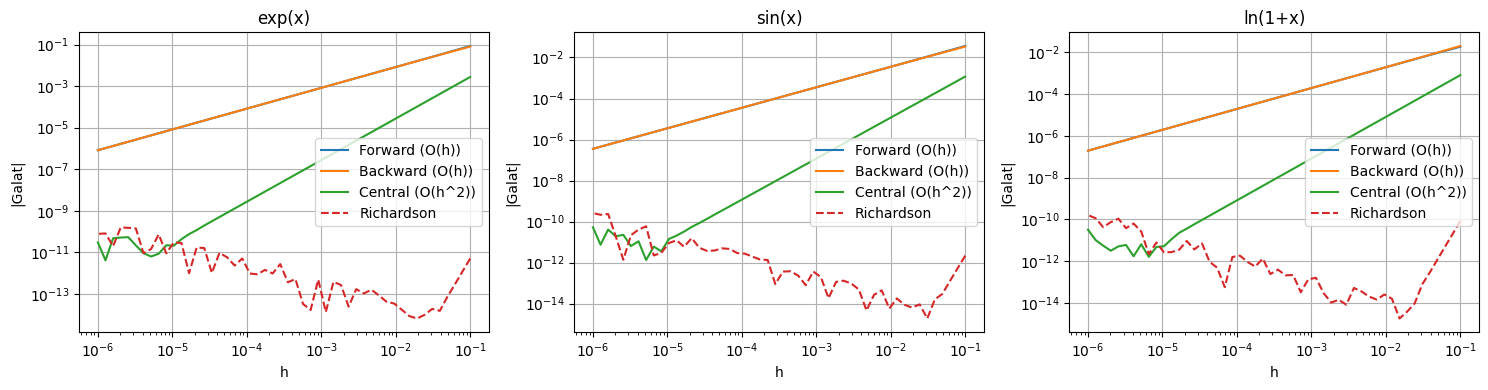

In [67]:
x1 = 0.5
x2 = np.pi / 4
x3 = 0.6

# Turunan pertama
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

eksperimen_df(axs[0], f1, df1_exact, x1, "exp(x)")
eksperimen_df(axs[1], f2, df2_exact, x2, "sin(x)")
eksperimen_df(axs[2], f3, df3_exact, x3, "ln(1+x)")

plt.tight_layout()
plt.show()

## 7.7. Eksperimen — Turunan Kedua (kurva galat & orde)

In [68]:
def eksperimen_d2f(ax, f, d2f_exact, x0, nama):
    # Membuat variasi nilai h dari 10^-1 sampai 10^-6 (log scale)
    # Digunakan untuk menganalisis pengaruh ukuran langkah terhadap galat turunan kedua
    h = np.logspace(-1, -6, 50)

    # List untuk menyimpan galat tiap metode
    err_f = []  # forward difference (turunan kedua)
    err_b = []  # backward difference
    err_c = []  # central difference
    err_r = []  # Richardson extrapolation

    # Loop untuk setiap nilai h
    for hi in h:
        # Hitung nilai eksak turunan kedua di titik x0
        # Digunakan sebagai acuan pembanding
        exact = d2f_exact(x0)

        # Hitung galat masing-masing metode:
        # galat = |nilai eksak - aproksimasi numerik|

        # Forward difference untuk turunan kedua
        # biasanya berorde O(h)
        ef = galat(exact, d2f_maju(f, x0, hi))

        # Backward difference untuk turunan kedua
        # juga berorde O(h)
        eb = galat(exact, d2f_mundur(f, x0, hi))

        # Central difference untuk turunan kedua
        # berorde O(h^2), lebih akurat
        ec = galat(exact, d2f_sentral(f, x0, hi))

        # Richardson extrapolation:
        # - menggunakan d2f_sentral sebagai metode dasar
        # - membentuk tabel Richardson (Romberg-style)
        # - meningkatkan orde akurasi secara bertahap
        er = galat(exact, richardson_table(d2f_sentral, f, x0, hi))

        # Simpan galat ke masing-masing list
        err_f.append(ef)
        err_b.append(eb)
        err_c.append(ec)
        err_r.append(er)

    # ---------------------------
    # VISUALISASI (LOG-LOG)
    # ---------------------------
    # Digunakan untuk melihat hubungan antara h dan galat
    # serta mengidentifikasi orde metode dari kemiringan grafik

    ax.loglog(h, err_f, label="Forward")
    ax.loglog(h, err_b, label="Backward")
    ax.loglog(h, err_c, label="Central (O(h^2))")

    # Richardson biasanya menghasilkan galat paling kecil
    # ditampilkan dengan garis putus-putus
    ax.loglog(h, err_r, '--', label="Richardson")

    # Label sumbu
    ax.set_xlabel("h")          # ukuran langkah
    ax.set_ylabel("|Galat|")    # error absolut

    # Judul subplot sesuai fungsi uji
    ax.set_title(f"{nama}")

    # Grid untuk mempermudah analisis visual
    ax.grid(True)

    # Legend untuk membedakan metode
    ax.legend()

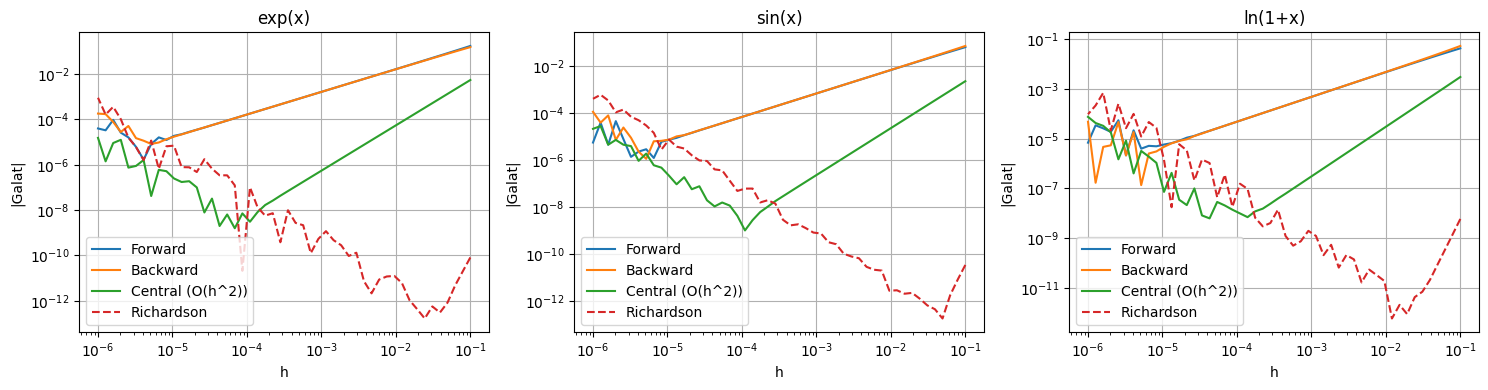

In [69]:
x1 = 0.5
x2 = np.pi / 4
x3 = 0.6

# Turunan kedua
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

eksperimen_d2f(axs[0], f1, d2f1_exact, x1, "exp(x)")
eksperimen_d2f(axs[1], f2, d2f2_exact, x2, "sin(x)")
eksperimen_d2f(axs[2], f3, d2f3_exact, x3, "ln(1+x)")

plt.tight_layout()
plt.show()


In [70]:
h = 0.2 #Misal


print("===== Turunan Pertama =====")
#Fungsi uji 1
print("----- Uji Fungsi 1 -----")
Xp = 0.5
n_asli = df1_exact(Xp)
n_aprox_f = df_maju(f1, Xp, h)
n_aprox_b = df_mundur(f1, Xp, h)
n_aprox_c = df_sentral(f1, Xp, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")


#Fungsi uji 2
print("----- Uji Fungsi 2 -----")
X0 = np.pi/4
n_asli = df2_exact(X0)
n_aprox_f = df_maju(f2, X0, h)
n_aprox_b = df_mundur(f2, X0, h)
n_aprox_c = df_sentral(f2, X0, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")


#Fungsi uji 3
print("----- Uji Fungsi 3 -----")
X0 = 0.6
n_asli = df3_exact(X0)
n_aprox_f = df_maju(f3, X0, h)
n_aprox_b = df_mundur(f3, X0, h)
n_aprox_c = df_sentral(f3, X0, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")

print("===== Turunan Kedua =====")
# Fungsi uji 1
print("----- Uji Fungsi 1 -----")
print(f"Asli = {n_asli}")
Xp = 0.5
n_asli = d2f1_exact(Xp)
n_aprox_f = d2f_maju(f1, Xp, h)
n_aprox_b = d2f_mundur(f1, Xp, h)
n_aprox_c = d2f_sentral(f1, Xp, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")

# Fungsi uji 2
print("----- Uji Fungsi 2 -----")
X0 = np.pi/4
n_asli = d2f2_exact(X0)
n_aprox_f = d2f_maju(f2, X0, h)
n_aprox_b = d2f_mundur(f2, X0, h)
n_aprox_c = d2f_sentral(f2, X0, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")

# Fungsi uji 3
print("----- Uji Fungsi 3 -----")
X0 = 0.6
n_asli = d2f3_exact(X0)
n_aprox_f = d2f_maju(f3, X0, h)
n_aprox_b = d2f_mundur(f3, X0, h)
n_aprox_c = d2f_sentral(f3, X0, h)
galat_m = galat(n_asli,n_aprox_f)
galat_b = galat(n_asli,n_aprox_b)
galat_c = galat(n_asli,n_aprox_c)
print(f"Asli = {n_asli}")
print(f"Aproksimasi Newton Beda Hingga Maju = {n_aprox_f}\tGalat = {galat_m}")
print(f"Aproksimasi Newton Beda Hingga Mundur = {n_aprox_b}\tGalat = {galat_b}")
print(f"Aproksimasi Newton Beda Hingga Sentral = {n_aprox_c}\tGalat = {galat_c}\n")

===== Turunan Pertama =====
----- Uji Fungsi 1 -----
Asli = 1.6487212707001282
Aproksimasi Newton Beda Hingga Maju = 1.8251571838517422	Galat = 0.176435913151614
Aproksimasi Newton Beda Hingga Mundur = 1.494312315620625	Galat = 0.15440895507950314
Aproksimasi Newton Beda Hingga Sentral = 1.6597347497361836	Galat = 0.011013479036055429

----- Uji Fungsi 2 -----
Asli = 0.7071067811865476
Aproksimasi Newton Beda Hingga Maju = 0.6319268651913446	Galat = 0.07517991599520302
Aproksimasi Newton Beda Hingga Mundur = 0.7728774449984671	Galat = 0.06577066381191954
Aproksimasi Newton Beda Hingga Sentral = 0.7024021550949058	Galat = 0.004704626091641795

----- Uji Fungsi 3 -----
Asli = 0.625
Aproksimasi Newton Beda Hingga Maju = 0.5889151782819171	Galat = 0.036084821718082916
Aproksimasi Newton Beda Hingga Mundur = 0.6676569631226137	Galat = 0.04265696312261369
Aproksimasi Newton Beda Hingga Sentral = 0.6282860707022654	Galat = 0.0032860707022653868

===== Turunan Kedua =====
----- Uji Fungsi 1 --

# Analisis Hasil Eksperimen

## Tujuan Eksperimen

Eksperimen ini bertujuan untuk membandingkan akurasi berbagai metode beda hingga dalam menghampiri turunan, yaitu:

- Beda maju (forward)
- Beda mundur (backward)
- Beda sentral (central)
- Richardson extrapolation (berbasis beda sentral)

Pengujian dilakukan pada beberapa fungsi:
- $f(x) = e^x$
- $f(x) = \sin(x)$
- $f(x) = \ln(1+x)$

---

## Pola Umum Grafik

Grafik ditampilkan dalam skala log-log antara $h$ dan galat.

Secara umum, semua metode menunjukkan pola:

1. Saat $h$ besar:
   - Galat besar (didominasi truncation error)

2. Saat $h$ mengecil:
   - Galat menurun

3. Saat $h$ sangat kecil:
   - Galat meningkat kembali (round-off error)

---

## Perbandingan Metode

### 1. Beda Maju dan Mundur

- Memiliki orde galat $O(h)$
- Kurva pada grafik lebih landai
- Penurunan galat relatif lambat
- Hasil forward dan backward hampir identik

**Kesimpulan:**
Metode ini kurang akurat dibanding metode lain, tetapi sederhana.

---

### 2. Beda Sentral

- Memiliki orde galat $O(h^2)$
- Kurva lebih curam dibanding forward/backward
- Galat lebih kecil untuk hampir semua nilai $h$

**Kesimpulan:**
Metode ini memberikan keseimbangan terbaik antara akurasi dan efisiensi.

---

### 3. Richardson Extrapolation

- Menggunakan pendekatan bertingkat (Romberg-style)
- Menghilangkan galat orde rendah secara sistematis
- Kurva berada paling bawah (galat terkecil)

**Kesimpulan:**
Metode paling akurat dalam eksperimen ini.

Namun:
- Sensitif terhadap round-off error saat $h$ sangat kecil
- Membutuhkan lebih banyak komputasi

---

## Pengaruh Fungsi yang Digunakan

### 1. Fungsi $e^x$

- Fungsi halus dan stabil
- Semua metode bekerja dengan baik
- Perbedaan akurasi terlihat jelas antar metode

---

### 2. Fungsi $\sin(x)$

- Fungsi periodik dan halus
- Pola galat mirip dengan $e^x$
- Metode sentral dan Richardson tetap unggul

---

### 3. Fungsi $\ln(1+x)$

- Memiliki perubahan gradien yang lebih tajam di dekat $x=0$
- Galat cenderung lebih besar dibanding fungsi lain
- Sensitivitas terhadap $h$ lebih tinggi

---

## Peran Nilai h

Nilai $h$ dibangkitkan dengan:

```python
np.logspace(-1, -6, 50)